In [42]:
import pandas as pd
df = pd.read_csv('tips.csv')

In [43]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [44]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [45]:
df = df.rename(columns={"sex": "gender"})
df

,total_bill,tip,gender,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [46]:
df.shape

(244, 7)

In [47]:
df.isna().sum()

total_bill    0
tip           0
gender        0
smoker        0
day           0
time          0
size          0
dtype: int64

In [48]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   gender      244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [50]:
df[df.duplicated()]

,total_bill,tip,gender,smoker,day,time,size
202,13.0,2.0,Female,Yes,Thur,Lunch,2


In [51]:
df.drop_duplicates(inplace=True)

In [52]:
df.groupby('gender')["tip"].sum()

gender
Female    244.51
Male      485.07
Name: tip, dtype: float64

In [53]:
df["total_bill"].mean()

np.float64(19.813868312757204)

In [54]:
df["gender"].value_counts()

gender
Male      157
Female     86
Name: count, dtype: int64

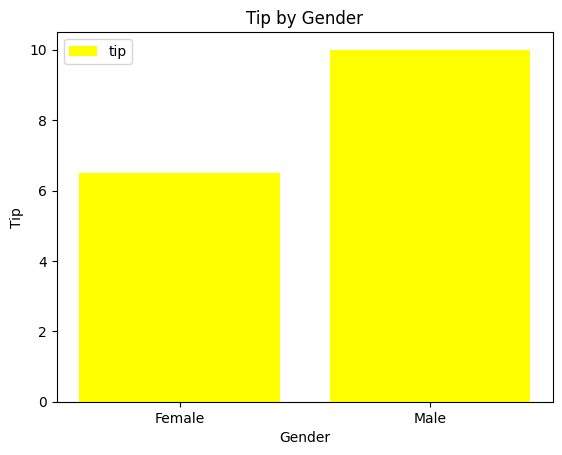

In [55]:
import matplotlib.pyplot as plt
plt.bar(df["gender"], df["tip"], color = "yellow" , label = "tip")
plt.xlabel("Gender")
plt.ylabel("Tip")
plt.title("Tip by Gender")
plt.legend()

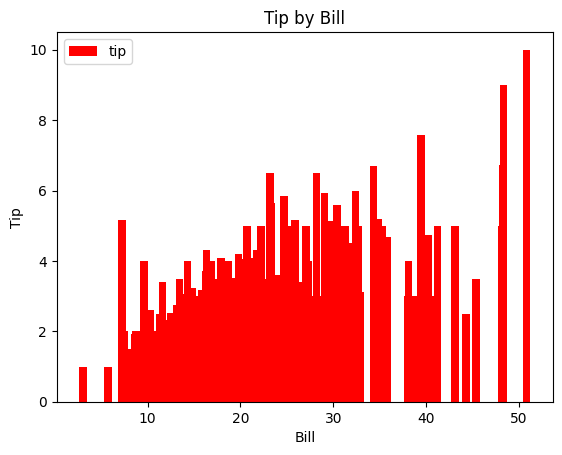

In [76]:
plt.bar(df["total_bill"], df["tip"], color = "red", label = "tip")
plt.xlabel("Bill")
plt.ylabel("Tip")
plt.title("Tip by Bill")
plt.legend()

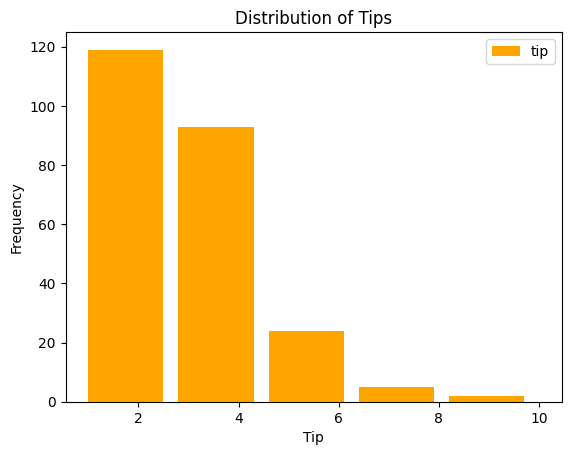

In [67]:
plt.hist(data = df, x = "tip", bins = 5,  color = "orange", width = 1.5, label = "tip")
plt.xlabel("Tip")
plt.ylabel("Frequency")
plt.title("Distribution of Tips")
plt.legend()

In [79]:
q1 = df["tip"].quantile(0.25)
q3 = df["tip"].quantile(0.75)
iqr = q3 - q1
high = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Above", round(high, 1), "is an outlier")

outliers = df[df["tip"] > high]
print("Number of outliers:", len(outliers))
outliers.sort_values("tip", ascending=False).head()

Q1: 2.0  Q3: 3.575  IQR: 1.6
Above 5.9 is an outlier
Number of outliers: 8


,total_bill,tip,gender,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
23,39.42,7.58,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
141,34.30,6.70,Male,No,Thur,Lunch,6


limit: -0.36250000000000027 to 5.9375
Q1: 2.0  Q3: 3.575  IQR: 1.6
Number of outliers: 8


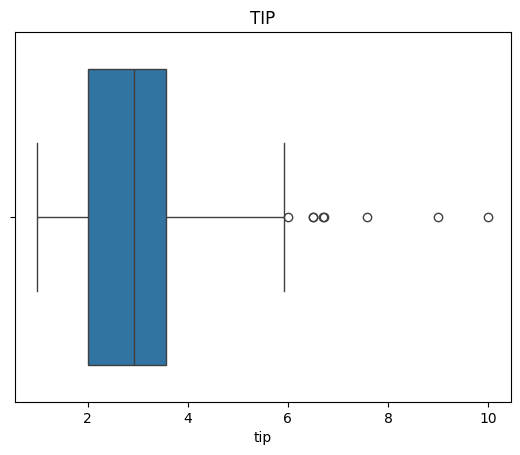

In [81]:
import seaborn as sns
q1 = df["tip"].quantile(0.25)
q3 = df["tip"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print("limit:", low, "to", high)

print("Q1:", q1, " Q3:", q3, " IQR:", round(iqr, 1))
print("Number of outliers:", len(outliers))
outliers.sort_values("tip", ascending=False).head()
sns.boxplot(data=df, x="tip")
plt.title("TIP")
plt.show()

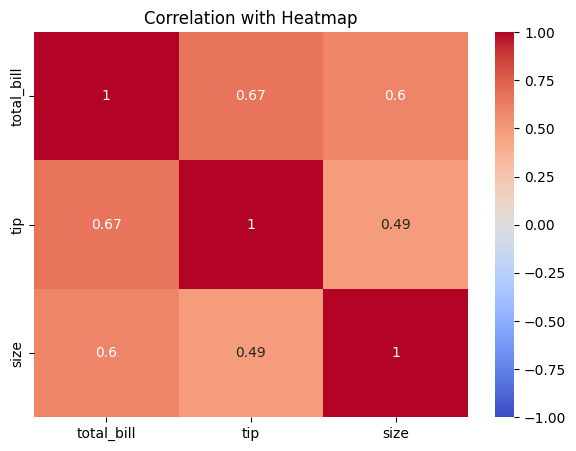

In [78]:
cols = ["total_bill", "tip", "size"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[cols].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation with Heatmap")
plt.show()